In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import math

In [4]:
df = pd.read_excel(r"C:\Users\Samanpreet Kaur\Desktop\bank-additional-full.xlsx")
df

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41183,73,retired,married,professional.course,no,yes,no,cellular,nov,fri,...,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,yes
41184,46,blue-collar,married,professional.course,no,no,no,cellular,nov,fri,...,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,no
41185,56,retired,married,university.degree,no,yes,no,cellular,nov,fri,...,2,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,no
41186,44,technician,married,professional.course,no,no,no,cellular,nov,fri,...,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,yes


In [5]:
df.shape

(41188, 21)

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  str    
 2   marital         41188 non-null  str    
 3   education       41188 non-null  str    
 4   default         41188 non-null  str    
 5   housing         41188 non-null  str    
 6   loan            41188 non-null  str    
 7   contact         41188 non-null  str    
 8   month           41188 non-null  str    
 9   day_of_week     41188 non-null  str    
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  str    
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null  float64
 1

In [7]:
print("missing:", df.isna().sum().sum(),"| duplicate rows:", df.duplicated().sum(),
)

missing: 0 | duplicate rows: 12


In [8]:
df = df.drop_duplicates().reset_index(drop=True)

In [9]:
print(" duplicate rows:", df.duplicated().sum())

 duplicate rows: 0


In [10]:
df['previously_contacted'] = np.where(df['pdays'] == 999, 'no', 'yes')
df['pdays'] = df['pdays'].replace(999, np.nan)

In [11]:
df = df.rename(columns={'y': 'subscribed'})

In [12]:
df['pdays'].isnull().sum()  
df['pdays'].mean()        

np.float64(6.014521452145215)

In [13]:
df.describe()

,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
count,41176.00000,41176.000000,41176.000000,1515.000000,41176.000000,41176.000000,41176.000000,41176.000000,41176.000000,41176.000000
mean,40.02380,258.315815,2.567879,6.014521,0.173013,0.081922,93.575720,-40.502863,3.621293,5167.034870
std,10.42068,259.305321,2.770318,3.824906,0.494964,1.570883,0.578839,4.627860,1.734437,72.251364
min,17.00000,0.000000,1.000000,0.000000,0.000000,-3.400000,92.201000,-50.800000,0.634000,4963.600000
25%,32.00000,102.000000,1.000000,3.000000,0.000000,-1.800000,93.075000,-42.700000,1.344000,5099.100000
50%,38.00000,180.000000,2.000000,6.000000,0.000000,1.100000,93.749000,-41.800000,4.857000,5191.000000
75%,47.00000,319.000000,3.000000,7.000000,0.000000,1.400000,93.994000,-36.400000,4.961000,5228.100000
max,98.00000,4918.000000,56.000000,27.000000,7.000000,1.400000,94.767000,-26.900000,5.045000,5228.100000


In [14]:
#Cleaning: “I removed 12 duplicate rows, leaving 41,176 customers. The value 999 in pdays is a placeholder for ‘never contacted before’, so I converted it to missing and added a previously_contacted flag. Only 1,515 customers had been contacted before, on average 6 days earlier.”

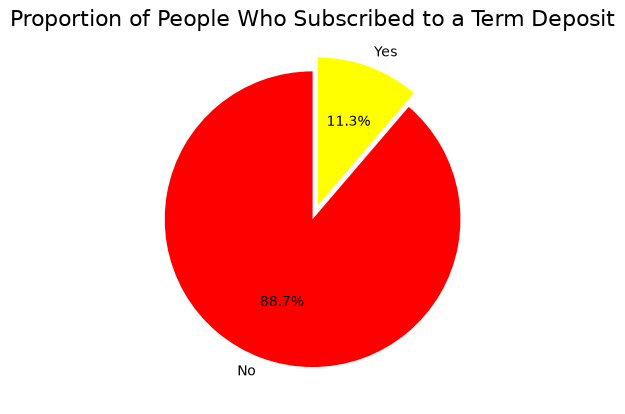

In [15]:
#•	What is the proportion of people who subscribed to a term deposit?
df["subscribed"].value_counts().plot.pie(autopct="%1.1f%%", colors=["red", "yellow"],labels=["No", "Yes"],startangle=90,explode=[0, 0.10])
plt.title("Proportion of People Who Subscribed to a Term Deposit", size=16)         
plt.show()

In [16]:
#Pie chart: “Only 11.3% of customers subscribed (4,639 of 41,176), while 88.7% declined. Overall conversion is low, so targeting matters more than call volume.”

In [32]:
#•	What is the correlation of age with other values?
df.corr(numeric_only=True)['age'].sort_values(ascending=False)


age               1.000000
cons.conf.idx     0.129075
sub_num           0.030381
previous          0.024379
euribor3m         0.010852
campaign          0.004622
cons.price.idx    0.001009
emp.var.rate     -0.000242
duration         -0.000808
nr.employed      -0.017607
pdays            -0.069608
Name: age, dtype: float64

In [33]:
#“Age has no meaningful linear relationship with any numeric variable. The strongest is consumer confidence at about 0.13, which is weak.”

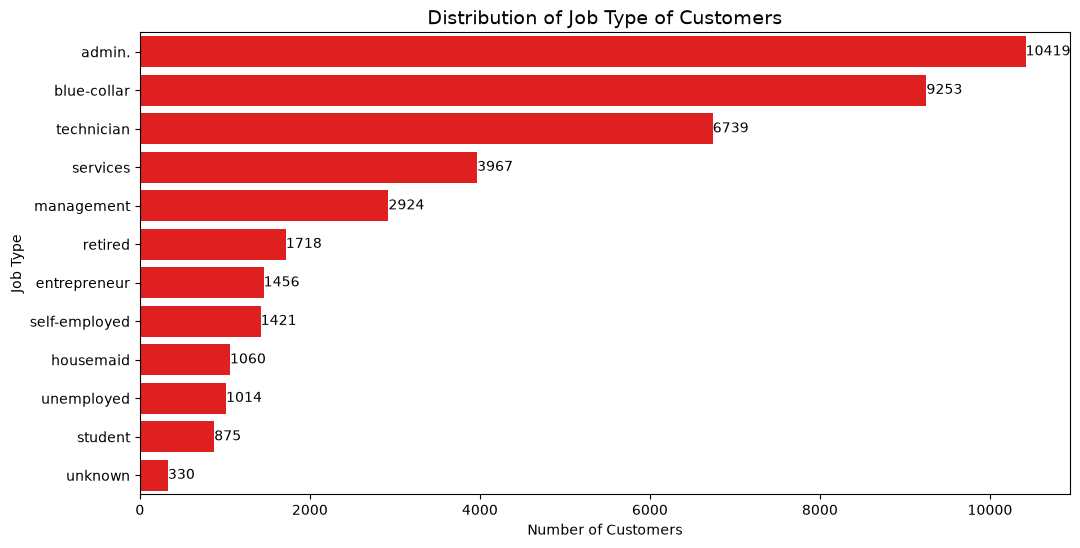

In [ ]:
#•	What is the distribution of the job type of the customers?
plt.figure(figsize=(12, 6))
ax=sns.countplot(y='job', data=df, order=df['job'].value_counts().index,color='red')
ax.bar_label(ax.containers[0])
plt.title('Distribution of Job Type of Customers', size=14)
plt.xlabel('Number of Customers')
plt.ylabel('Job Type')
plt.show()

In [35]:
#Admin, blue-collar and technician roles make up about 64% of customers, so the campaign mostly reached these groups.

In [34]:
#•	What is the average duration of the calls?
df['duration'].describe()

count    41176.000000
mean       258.315815
std        259.305321
min          0.000000
25%        102.000000
50%        180.000000
75%        319.000000
max       4918.000000
Name: duration, dtype: float64

In [23]:
avg = df['duration'].mean()
print("Average duration (seconds):", round(avg, 1))
print("Average duration (minutes):", round(avg / 60, 1))

Average duration (seconds): 258.3
Average duration (minutes): 4.3


In [ ]:
#The average call is 4.3 minutes (258 seconds), but the median is only 3 minutes. A few very long calls, up to 82 minutes, pull the average up.

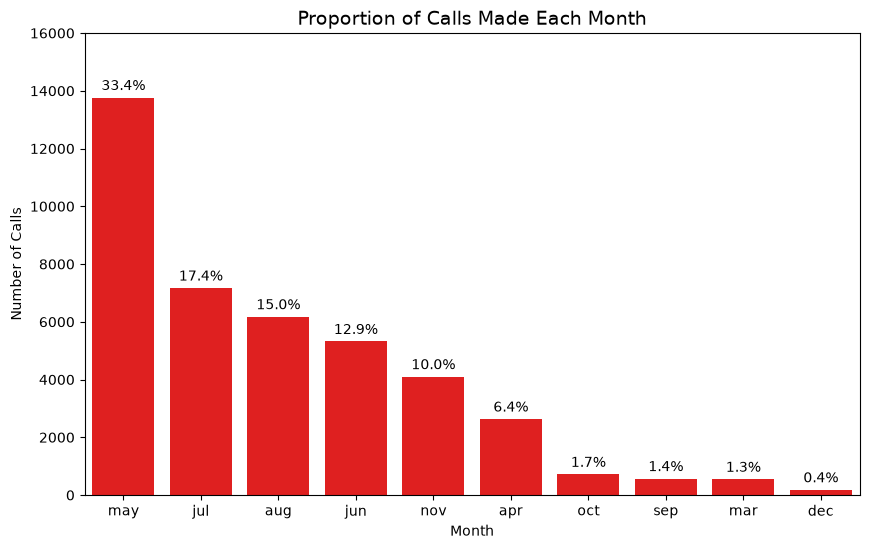

In [ ]:
#•	What is the proportion of calls made each month?
plt.figure(figsize=(10, 6))
ax = sns.countplot(x='month', data=df, order=df['month'].value_counts().index,color="red")

total = len(df)
labels = [f"{bar.get_height() / total * 100:.1f}%" for bar in ax.patches]
ax.bar_label(ax.containers[0], labels=labels, padding=3)

plt.title('Proportion of Calls Made Each Month', size=14)
plt.xlabel('Month')
plt.ylabel('Number of Calls')
plt.ylim(0, 16000)
plt.show()

In [36]:
#May alone accounts for 33.4% of all calls, and May to August together for about 79%. There are no calls in January or February, so the campaign was strongly seasonal

In [ ]:
#Subscription rate by number of contacts
df['sub_num'] = df['subscribed'].map({'yes': 1, 'no': 0})

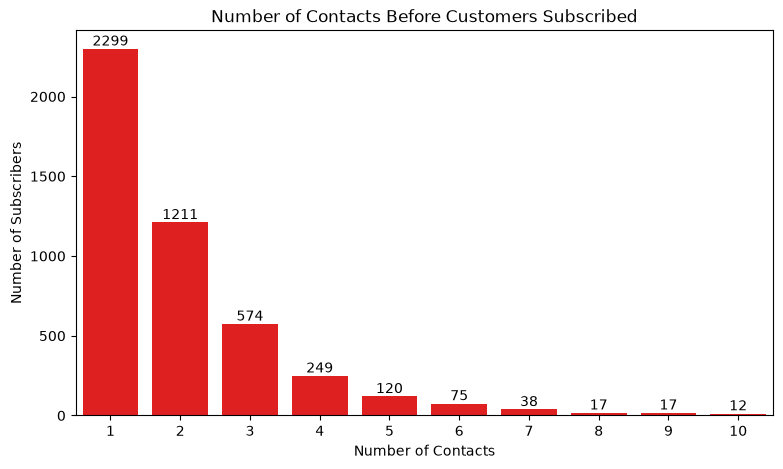

In [28]:
yes_df = df[(df['subscribed'] == 'yes') & (df['campaign'] <= 10)]

plt.figure(figsize=(9, 5))
ax = sns.countplot(x='campaign', data=yes_df, color='red')
ax.bar_label(ax.containers[0])
plt.title('Number of Contacts Before Customers Subscribed')
plt.xlabel('Number of Contacts')
plt.ylabel('Number of Subscribers')
plt.show()

In [38]:
#Most subscribers, 2,299, said yes on the first contact, and numbers fall with each extra call. Because most customers were only called once or twice, I also looked at rates

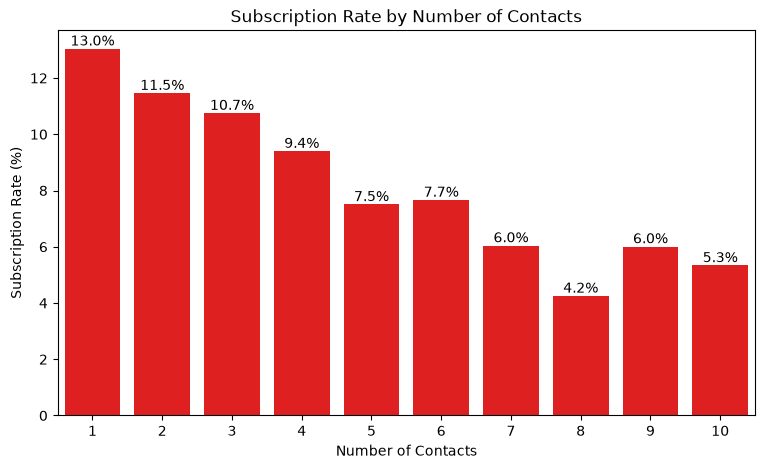

In [30]:
#Subscription rate by number of contacts
rate = df[df['campaign'] <= 10].groupby('campaign')['sub_num'].mean() * 100

plt.figure(figsize=(9, 5))
ax = sns.barplot(x=rate.index, y=rate.values, color='red')
ax.bar_label(ax.containers[0], fmt='%.1f%%')
plt.title('Subscription Rate by Number of Contacts')
plt.xlabel('Number of Contacts')
plt.ylabel('Subscription Rate (%)')
plt.show()

In [ ]:
#The success rate is 13.0% on the first contact and falls to about 5% by the tenth. Repeated calling gives diminishing returns, so contact attempts could be capped

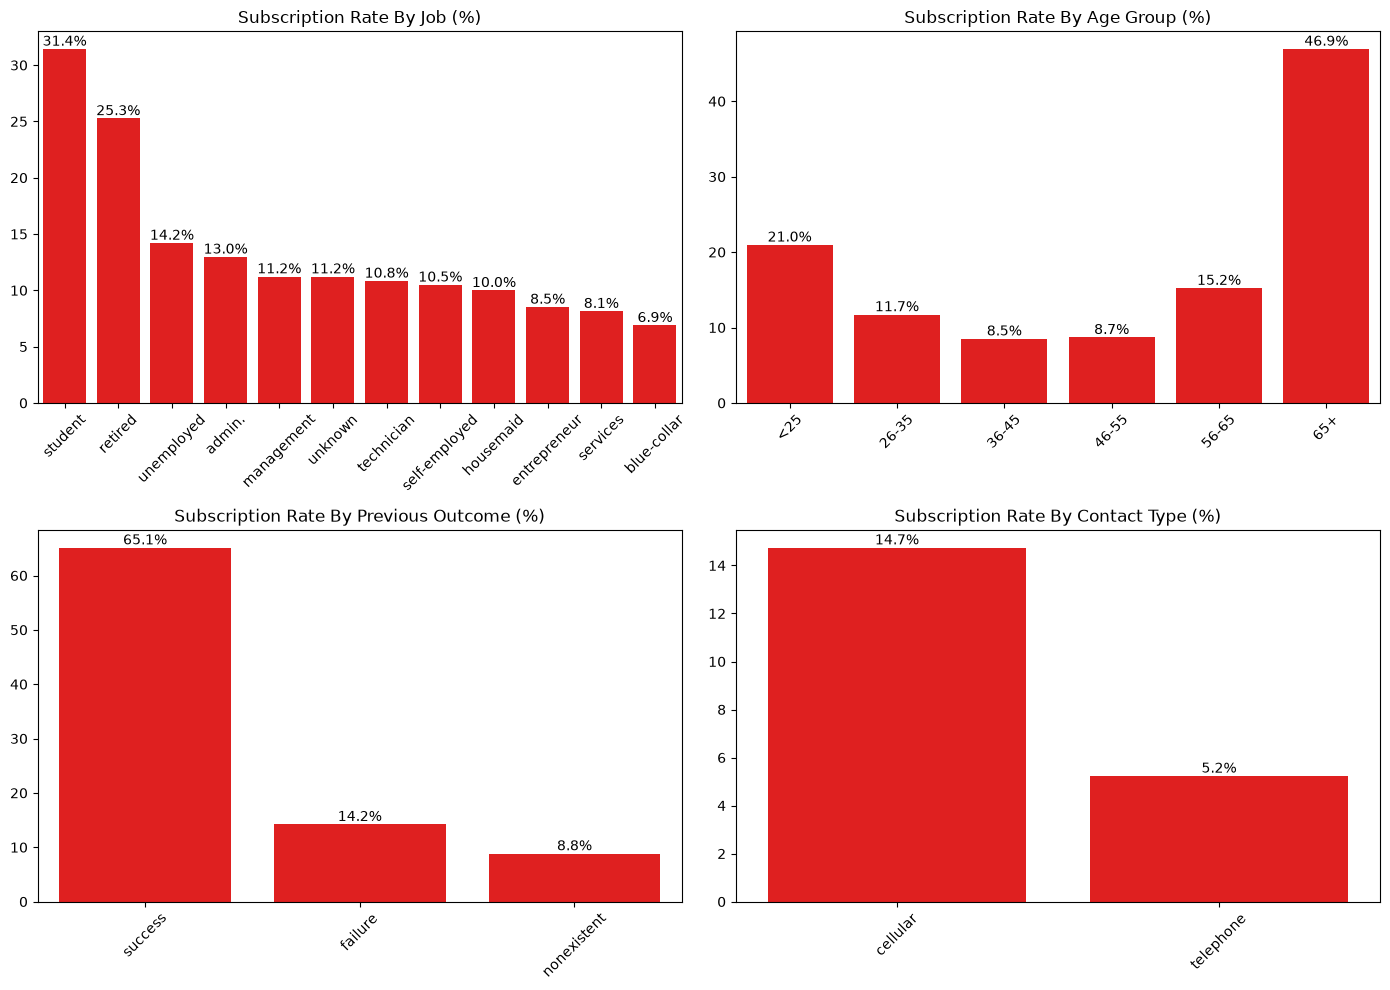

In [31]:
df['sub_num'] = df['subscribed'].map({'yes': 1, 'no': 0})
df['age_group'] = pd.cut(df['age'], [0, 25, 35, 45, 55, 65, 100],labels=['<25', '26-35', '36-45', '46-55', '56-65', '65+'])
fig, axes = plt.subplots(2, 2, figsize=(14, 10),)
charts = [('job', 'By Job'), ('age_group', 'By Age Group'),
          ('poutcome', 'By Previous Outcome'), ('contact', 'By Contact Type')]

for ax, (col, title) in zip(axes.flatten(), charts):
    rate = df.groupby(col, observed=True)['sub_num'].mean().mul(100).sort_values(ascending=False)
    sns.barplot(x=rate.index, y=rate.values, ax=ax,color="red")
    ax.bar_label(ax.containers[0], fmt='%.1f%%')
    ax.set_title(f'Subscription Rate {title} (%)')
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

In [ ]:
#Students (31.4%) and retired customers (25.3%) convert best, and blue-collar customers (6.9%) convert least.
#Customers over 65 (46.9%) and 25 or under (21.0%) convert far above the 8–12% of ages 26–55.
#Customers who subscribed in an earlier campaign convert at 65.1%, against 8.8% for first-time contacts.
#Cellular contacts convert at 14.7%, nearly three times the 5.2% for landlines.